# FRAUD DETECTION SYSTEM
#### The goal is to build a machine learning-powered fraud detection system that evaluates financial transactions that identifies potentially fraudulent activity, and flags suspicious transactions before they are completed.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
import shutil
from pathlib import Path

In [2]:
# Creating Data folder where we will store our csv file
data_folder = Path("data")
data_folder.mkdir(exist_ok=True)

In [3]:
# Coping the dataset
source = Path(r"C:\Users\USER\Downloads\PS_20174392719_1491204439457_log.csv")

destination = data_folder / source.name

shutil.copy2(source, destination)

WindowsPath('data/PS_20174392719_1491204439457_log.csv')

In [4]:
# Confirming if file is copied
destination.exists()

True

In [5]:
# Loading Datatset
df = pd.read_csv(destination)

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


# EDA

In [6]:
df.shape

(1048575, 11)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 11 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   step            1048575 non-null  int64  
 1   type            1048575 non-null  str    
 2   amount          1048575 non-null  float64
 3   nameOrig        1048575 non-null  str    
 4   oldbalanceOrg   1048575 non-null  float64
 5   newbalanceOrig  1048575 non-null  float64
 6   nameDest        1048575 non-null  str    
 7   oldbalanceDest  1048575 non-null  float64
 8   newbalanceDest  1048575 non-null  float64
 9   isFraud         1048575 non-null  int64  
 10  isFlaggedFraud  1048575 non-null  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 88.0 MB


In [8]:
# Checking for any duplicates
df[df.duplicated()]

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud


#### What we want is to build a fraud detection that's able to detect a fraud before a tranasaction. So we would not use columns like 'oldbalanceOrg', 'newbalanceOrg', 'oldbalanceDest' & 'newbalanceDest'

In [9]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [10]:
df_new = df[['step', 'type', 'amount', 'nameOrig', 
             'nameDest', 'isFraud', 'isFlaggedFraud']]

In [11]:
df_new.head()

,step,type,amount,nameOrig,nameDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,M1979787155,0,0
1,1,PAYMENT,1864.28,C1666544295,M2044282225,0,0
2,1,TRANSFER,181.00,C1305486145,C553264065,1,0
3,1,CASH_OUT,181.00,C840083671,C38997010,1,0
4,1,PAYMENT,11668.14,C2048537720,M1230701703,0,0


In [12]:
# Renaming columns
df_new.columns = df_new.columns.str.lower()

df_new.columns

Index(['step', 'type', 'amount', 'nameorig', 'namedest', 'isfraud',
       'isflaggedfraud'],
      dtype='str')

In [13]:
# Renaming my str variables
strings = df_new.dtypes[df_new.dtypes == 'str'].index

for col in strings:
    df_new[col] = df_new[col].str.lower().str.replace(' ', '_')

df_new.head()

,step,type,amount,nameorig,namedest,isfraud,isflaggedfraud
0,1,payment,9839.64,c1231006815,m1979787155,0,0
1,1,payment,1864.28,c1666544295,m2044282225,0,0
2,1,transfer,181.00,c1305486145,c553264065,1,0
3,1,cash_out,181.00,c840083671,c38997010,1,0
4,1,payment,11668.14,c2048537720,m1230701703,0,0


In [14]:
# Checking unique values in each feature
for col in df_new.columns:
    print(col)
    print(df_new[col].unique())
    print("--------------------")

step
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72
 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95]
--------------------
type
<StringArray>
['payment', 'transfer', 'cash_out', 'debit', 'cash_in']
Length: 5, dtype: str
--------------------
amount
[ 9839.64  1864.28   181.   ...  9917.36 14140.05 11450.03]
--------------------
nameorig
<StringArray>
['c1231006815', 'c1666544295', 'c1305486145',  'c840083671', 'c2048537720',
   'c90045638',  'c154988899', 'c1912850431', 'c1265012928',  'c712410124',
 ...
 'c1654402840',  'c565523855',  'c990252469',  'c954269986', 'c2113264897',
 'c1179511630', 'c1956161225', 'c2037964975', 'c1633237354', 'c1264356443']
Length: 1048317, dtype: str
--------------------
namedest
<StringArray>
['m1979787155', 'm2044282225',  'c553264065',   'c38997010', 'm1230701703'

In [15]:
df_new['isflaggedfraud'].nunique()

1

#### isFlaggedFraud contains only zeros in our dataset, it has zero variance.

#### This means the column cannot help my model distinguish fraudulent transactions from legitimate ones.

# FEATURE IMPORTANCE: MUTUAL INFORMATION

In [16]:
categorical = ['type', 'nameorig', 'namedest']

from sklearn.metrics import mutual_info_score

def mutual_info_isfraud_score(series):
    return mutual_info_score(df_new.isfraud, series)

mi = df_new[categorical].apply(mutual_info_isfraud_score)
mi.sort_values(ascending=False)

nameorig    0.008519
namedest    0.006532
type        0.001156
dtype: float64

#### I would still exclude 'nameorig' & 'namedest' from our initial model. Why:
#### - Unseen accounts: A model may encounter account IDs it has never seen during training.
#### - Overfitting: The model may memorise account-specific patterns instead of learning general fraud behaviour.

# FEATURE IMPORTANCE: CORRELATION

In [17]:
numerical = ['step', 'amount']

df_new[numerical].corrwith(df_new.isfraud)

step      0.045030
amount    0.128862
dtype: float64

## Observations:

#### Step (0.045030)
#### - There is a very weak positive linear relationship between transaction time and fraud.
#### - This suggests that step alone does not explain much about fraudulent transactions.
#### Amount (0.128862)
#### - There is a weak positive linear relationship between transaction amount and fraud.
#### - This suggests that larger transaction amounts tend to be associated with fraud, although the relationship is not strong.

In [18]:
# Our new dataframe
df_new = df_new[['step', 'type', 'amount', 'isfraud']]

In [19]:
df_new.head()

,step,type,amount,isfraud
0,1,payment,9839.64,0
1,1,payment,1864.28,0
2,1,transfer,181.00,1
3,1,cash_out,181.00,1
4,1,payment,11668.14,0


In [20]:
# Lets check the distribution of isfraud feature
df_new['isfraud'].value_counts()

isfraud
0    1047433
1       1142
Name: count, dtype: int64

In [21]:
df_new['isfraud'].value_counts(normalize=True) * 100

isfraud
0    99.89109
1     0.10891
Name: proportion, dtype: float64

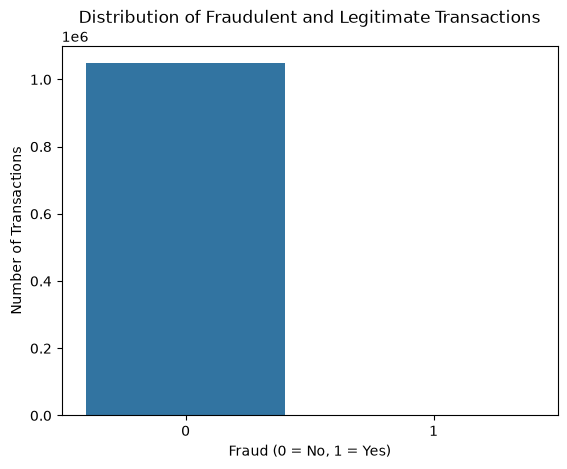

In [22]:
# Plot our distribution
sns.countplot(data=df_new, x='isfraud')

plt.title('Distribution of Fraudulent and Legitimate Transactions')
plt.xlabel('Fraud (0 = No, 1 = Yes)')
plt.ylabel('Number of Transactions')
plt.show()

##### The dataset has many more legitimate transactions than fraudulent ones. About 99.89% of the transactions are legitimate, while only 0.11% are fraudulent. This means a model could achieve high accuracy by simply predicting all transactions as legitimate, even though it would fail to detect fraud. For this reason, we will not rely on accuracy alone. Instead, we will use precision, recall, F1-score and PR-AUC to better evaluate how well our models detect fraudulent transactions.

# SPLITTING OUR DATA OR VALIDATION FRAMEWORK

In [23]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df_new, test_size=0.2, random_state=1, stratify=df_new.isfraud)

df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1, stratify=df_full_train.isfraud)

#### We use stratify to ensure that the training, validation and test sets maintain approximately the same proportion of fraudulent and legitimate transactions because its highly imbalanced.

In [24]:
len(df_train), len(df_val), len(df_test)

(629145, 209715, 209715)

In [25]:
df_train = df_train.reset_index(drop='True')
df_val = df_val.reset_index(drop='True')
df_test = df_test.reset_index(drop='True')

In [26]:
y_train = df_train.isfraud.values
y_test = df_test.isfraud.values
y_val = df_val.isfraud.values

In [27]:
del df_train['isfraud']
del df_val['isfraud']
del df_test['isfraud']

In [28]:
# Lets check if startification worked
for name, y in [
    ('Training', y_train),
    ('Validation', y_val),
    ('Testing', y_test)
]:
    print(name)
    print(pd.Series(y).value_counts(normalize=True) * 100)
    print('--------------------')

Training
0    99.891122
1     0.108878
Name: proportion, dtype: float64
--------------------
Validation
0    99.890804
1     0.109196
Name: proportion, dtype: float64
--------------------
Testing
0    99.891281
1     0.108719
Name: proportion, dtype: float64
--------------------


##### We used stratified sampling when splitting the dataset to ensure that the training, validation and testing sets maintain approximately the same proportion of legitimate and fraudulent transactions. The results show that all three datasets have almost identical distributions. This will help us train and evaluate our models fairly.

# ONEHOTENCODING

In [29]:
categorical = ['type']

numerical = ['step', 'amount']

In [30]:
# Import DictVectorizer
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

In [31]:
train_dict = df_train[categorical + numerical].to_dict(orient='records')

X_train = dv.fit_transform(train_dict)

# Same for validation data
val_dict = df_val[categorical + numerical].to_dict(orient='records')

X_val = dv.transform(val_dict)

In [32]:
print(X_train.shape)
print(X_val.shape)
print(dv.get_feature_names_out())

(629145, 7)
(209715, 7)
['amount' 'step' 'type=cash_in' 'type=cash_out' 'type=debit'
 'type=payment' 'type=transfer']


# LOGISTIC REGRESSION

In [33]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

C:\Users\USER\OneDrive\Desktop\SQL_and_Excel_Files\Fraud_detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [34]:
# Soft predictions. Comes into 2 columns left = 0 & Right = 1. We only need the right part
model.predict_proba(X_val)

array([[9.98041096e-01, 1.95890356e-03],
       [9.99410970e-01, 5.89029534e-04],
       [9.97758157e-01, 2.24184254e-03],
       ...,
       [9.99948767e-01, 5.12330651e-05],
       [9.99546497e-01, 4.53502971e-04],
       [9.98664133e-01, 1.33586748e-03]], shape=(209715, 2))

In [35]:
y_pred = model.predict_proba(X_val)[:,1]

y_pred

array([1.95890356e-03, 5.89029534e-04, 2.24184254e-03, ...,
       5.12330651e-05, 4.53502971e-04, 1.33586748e-03], shape=(209715,))

In [36]:
# If the model thinks the probability of isfraud is 50% or more, we predict that the customer will fraud.
isfraud_decision = (y_pred >= 0.5)

In [37]:
y_val[0:30]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0])

In [38]:
isfraud_decision.astype(int)[0:30]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0])

##### We used predict_proba() to obtain the probability of each transaction being legitimate or fraudulent. We selected the fraud probabilities and applied a threshold of 0.5 to classify transactions. Any transaction with a fraud probability of 0.5 or higher is classified as fraudulent, while the rest are classified as legitimate.

# MODEL EVALUATION

In [39]:
from sklearn.metrics import accuracy_score

accuracy_score(y_val, isfraud_decision)

0.998960494003767

# CONFUSSION MATRIX

In [40]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_val, isfraud_decision)

array([[209481,      5],
       [   213,     16]])

### Confusion Matrix
**Observations:**

- The model correctly identified most legitimate transactions.
- Out of 229 actual fraudulent transactions, it detected only 16.
- It failed to detect 213 fraudulent transactions, classifying them as legitimate.

#### Conclusion

The confusion matrix reveals that Logistic Regression performs well at identifying legitimate transactions but struggles to detect fraudulent activity. We need to explore other models that can improve fraud detection.


# PRECISION, RECALL & F1-SCORE

In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score

print('Precision:', precision_score(y_val, isfraud_decision))
print('Recall:', recall_score(y_val, isfraud_decision))
print('F1-score:', f1_score(y_val, isfraud_decision))

Precision: 0.7619047619047619
Recall: 0.06986899563318777
F1-score: 0.128


### Evaluation Metrics – Logistic Regression

#### 1. Precision – 76.19%

**What does precision measure?**

Precision tells us how often the model is correct when it predicts that a transaction is fraudulent.

- The model flagged 21 transactions as fraudulent.
- Out of these, 16 were actually fraudulent.

**Interpretation:** The model was correct approximately 76% of the time when it flagged a transaction as fraud.

#### 2. Recall – 6.98%

**What does recall measure?**

Recall tells us how many of the actual fraudulent transactions the model successfully detected.

- There were 229 actual fraudulent transactions.
- The model detected only 16 of them.

**Interpretation:** The model detected only about 7 out of every 100 fraudulent transactions, meaning it missed most fraudulent activity.

#### 3. F1-Score – 12.80%

**What does F1-score measure?**

F1-score combines precision and recall into a single metric. It is the harmonic mean of the two:

**Interpretation:** The F1-score is low because the model has reasonably good precision but very poor recall. Although most transactions flagged as fraud are genuinely fraudulent, the model fails to detect the majority of actual fraud cases.

#### Conclusion

The Logistic Regression model achieves good precision but performs poorly in detecting fraudulent transactions. Its low recall means that many fraudulent transactions go undetected.

This suggests that we need to explore other machine learning models that can improve fraud detection, particularly recall, while maintaining reasonable precision.


# DECISSION TREE

In [42]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

isfraud_decision = (y_pred >= 0.5)

In [43]:
print('Accuracy:', accuracy_score(y_val, isfraud_decision))
print('Confusion Matrix:\n', confusion_matrix(y_val, isfraud_decision))
print('Precision:', precision_score(y_val, isfraud_decision))
print('Recall:', recall_score(y_val, isfraud_decision))
print('F1-score:', f1_score(y_val, isfraud_decision))

Accuracy: 0.9994468683689769
Confusion Matrix:
 [[209485      1]
 [   115    114]]
Precision: 0.991304347826087
Recall: 0.4978165938864629
F1-score: 0.6627906976744186


### Decision Tree Classifier

#### 1. Accuracy – 99.94%
**Interpretation:** The model correctly classified approximately 99.94% of all transactions. However, because our dataset is highly imbalanced, accuracy alone is not sufficient to evaluate the model's performance.

#### 2. Confusion Matrix

The confusion matrix shows how the model classified legitimate and fraudulent transactions.
**Observations:**

- **True Negatives (209,485):** Correctly identified legitimate transactions.
- **False Positives (1):** One legitimate transaction was incorrectly classified as fraudulent.
- **False Negatives (115):** Failed to detect 115 actual fraudulent transactions.
- **True Positives (114):** Correctly identified 114 fraudulent transactions.

**Interpretation:** The model produces very few false fraud alerts, but it still misses approximately half of the actual fraudulent transactions.

#### 3. Precision – 99.13%
**Interpretation:** Approximately 99% of transactions flagged as fraudulent were actually fraudulent. This means the model produces very few false fraud alerts.

#### 4. Recall – 49.78%
**Interpretation:** The model detected approximately 50% of all fraudulent transactions. However, it still missed 115 out of 229 actual fraud cases.

#### 5. F1-Score – 66.28%
**Interpretation:** The F1-score shows a considerable improvement compared with Logistic Regression. The Decision Tree achieves an excellent precision of 99.13% and a much better recall of 49.78%.

#### Conclusion

Compared with Logistic Regression, the Decision Tree significantly improves fraud detection.

- Precision increased from 76.19% to 99.13%.
- Recall increased from 6.98% to 49.78%.
- F1-score increased from 12.80% to 66.28%.

The Decision Tree is much better at identifying fraudulent transactions while producing very few false alerts. However, it still misses approximately half of all fraudulent transactions, so we should explore whether another model can improve recall without significantly reducing precision.


# RANDOM FOREST

In [44]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [45]:
# Make predictions
y_pred = model.predict_proba(X_val)[:, 1]

isfraud_decision = (y_pred >= 0.5)

In [46]:
# Model evaluation
print('Accuracy:', accuracy_score(y_val, isfraud_decision))
print('Confusion Matrix:\n', confusion_matrix(y_val, isfraud_decision))
print('Precision:', precision_score(y_val, isfraud_decision))
print('Recall:', recall_score(y_val, isfraud_decision))
print('F1-score:', f1_score(y_val, isfraud_decision))

Accuracy: 0.9993228905896097
Confusion Matrix:
 [[209444     42]
 [   100    129]]
Precision: 0.7543859649122807
Recall: 0.5633187772925764
F1-score: 0.645



### Random Forest Observations

The Random Forest model achieved an accuracy of 99.93%. However, accuracy alone is not sufficient to evaluate the model because the dataset is highly imbalanced.

The confusion matrix shows that the model correctly identified 129 fraudulent transactions and 209,444 legitimate transactions. It incorrectly classified 42 legitimate transactions as fraudulent and failed to identify 100 fraudulent transactions.

The precision of 75.44% indicates that approximately 75% of the transactions predicted as fraudulent were actually fraudulent.

The recall of 56.33% indicates that the model successfully identified approximately 56% of all fraudulent transactions, missing 100 out of 229 fraudulent transactions.

The F1-score of 64.5% shows the balance between precision and recall.

### Comparison of the Three Models

| Metric | Logistic Regression | Decision Tree | Random Forest |
|---|---:|---:|---:|
| Accuracy | 99.90% | 99.94% | 99.93% |
| Precision | 76.19% | 99.13% | 75.44% |
| Recall | 6.99% | 49.78% | 56.33% |
| F1-score | 12.80% | 66.28% | 64.50% |
| Fraud detected | 16 | 114 | 129 |
| Fraud missed | 213 | 115 | 100 |

### Conclusion

Random Forest achieved the highest recall, identifying 129 fraudulent transactions compared to 114 for Decision Tree and 16 for Logistic Regression.

Decision Tree achieved the highest precision and F1-score, indicating a better balance between precision and recall at the default classification threshold of 0.5.

Overall, Random Forest is better at identifying fraudulent transactions, while Decision Tree produces fewer false fraud alerts.

Further experiments with classification thresholds are necessary to determine whether we can improve recall while maintaining reasonable precision.


# THRESHHOLDS

In [47]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for threshold in thresholds:
    isfraud_decision = (y_pred >= threshold)

    print(f'Threshold: {threshold}')
    print('Precision:', precision_score(y_val, isfraud_decision))
    print('Recall:', recall_score(y_val, isfraud_decision))
    print('F1-score:', f1_score(y_val, isfraud_decision))
    print()

Threshold: 0.1
Precision: 0.35459183673469385
Recall: 0.6069868995633187
F1-score: 0.4476650563607085

Threshold: 0.2
Precision: 0.5018450184501845
Recall: 0.5938864628820961
F1-score: 0.544

Threshold: 0.3
Precision: 0.5702127659574469
Recall: 0.5851528384279476
F1-score: 0.5775862068965517

Threshold: 0.4
Precision: 0.6208530805687204
Recall: 0.5720524017467249
F1-score: 0.5954545454545455

Threshold: 0.5
Precision: 0.7543859649122807
Recall: 0.5633187772925764
F1-score: 0.645

Threshold: 0.6
Precision: 0.8503401360544217
Recall: 0.5458515283842795
F1-score: 0.6648936170212766

Threshold: 0.7
Precision: 0.9761904761904762
Recall: 0.537117903930131
F1-score: 0.6929577464788732

Threshold: 0.8
Precision: 0.9916666666666667
Recall: 0.519650655021834
F1-score: 0.6819484240687679

Threshold: 0.9
Precision: 1.0
Recall: 0.5065502183406113
F1-score: 0.672463768115942



### Classification Threshold Observations

We initially used a classification threshold of 0.5 to classify transactions as fraudulent or legitimate. However, we experimented with different thresholds to understand how they affect precision, recall and F1-score.

At a threshold of 0.1, the model achieved the highest recall of 60.70%, meaning it identified more fraudulent transactions. However, precision dropped to 35.46%, resulting in more false fraud alerts.

As the threshold increased, precision generally improved while recall decreased. This happens because the model becomes more selective when classifying transactions as fraudulent.

At a threshold of 0.7, the model achieved the highest F1-score of 69.30%, with precision of 97.62% and recall of 53.71%.

At a threshold of 0.9, precision reached 100%, but recall decreased to 50.66%, meaning the model missed more fraudulent transactions.

### Conclusion

A threshold of 0.7 produced the highest F1-score among the thresholds tested. It provides a better balance between precision and recall compared to the default threshold of 0.5.

However, the choice of threshold depends on the business objective. In fraud detection, missing fraudulent transactions can be costly, so recall is also an important consideration.

Further evaluation is required before selecting the final threshold.


In [48]:
thresholds = np.arange(0.60, 0.81, 0.01)

results = []

for threshold in thresholds:
    isfraud_decision = (y_pred >= threshold)

    precision = precision_score(y_val, isfraud_decision)
    recall = recall_score(y_val, isfraud_decision)
    f1 = f1_score(y_val, isfraud_decision)

    results.append({
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'f1_score': f1
    })

df_thresholds = pd.DataFrame(results)

df_thresholds.sort_values(
    by='f1_score',
    ascending=False
)

,threshold,precision,recall,f1_score
7,0.67,0.954198,0.545852,0.694444
9,0.69,0.976190,0.537118,0.692958
6,0.66,0.946970,0.545852,0.692521
8,0.68,0.953846,0.541485,0.690808
5,0.65,0.932836,0.545852,0.688705
10,0.70,0.983740,0.528384,0.687500
16,0.76,0.991736,0.524017,0.685714
15,0.75,0.991736,0.524017,0.685714
21,0.81,1.000000,0.519651,0.683908
20,0.80,1.000000,0.519651,0.683908


### Observations

The threshold of 0.67 provides the best balance between precision and recall among the thresholds tested.

We will use 0.67 as our selected classification threshold for the Random Forest model, subject to final evaluation on the test dataset.


In [49]:
test_dict = df_test[categorical + numerical].to_dict(orient='records')

X_test = dv.transform(test_dict)

y_pred_test = model.predict_proba(X_test)[:, 1]

isfraud_test = (y_pred_test >= 0.67)

In [50]:
# Final Metrics
print('Accuracy:', accuracy_score(y_test, isfraud_test))
print('Confusion Matrix:\n', confusion_matrix(y_test, isfraud_test))
print('Precision:', precision_score(y_test, isfraud_test))
print('Recall:', recall_score(y_test, isfraud_test))
print('F1-score:', f1_score(y_test, isfraud_test))

Accuracy: 0.999485015378013
Confusion Matrix:
 [[209479      8]
 [   100    128]]
Precision: 0.9411764705882353
Recall: 0.5614035087719298
F1-score: 0.7032967032967034


# XGBOOST

In [51]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

model_xgb.fit(X_train, y_train)

# Make predictions
y_pred_xgb = model_xgb.predict_proba(X_val)[:, 1]

isfraud_decision_xgb = (y_pred_xgb >= 0.5).astype(int)

In [52]:
print('Accuracy:', accuracy_score(y_val, isfraud_decision_xgb))
print('Confusion Matrix:\n', confusion_matrix(y_val, isfraud_decision_xgb))
print('Precision:', precision_score(y_val, isfraud_decision_xgb))
print('Recall:', recall_score(y_val, isfraud_decision_xgb))
print('F1-score:', f1_score(y_val, isfraud_decision_xgb))

Accuracy: 0.96464249099969
Confusion Matrix:
 [[202117   7369]
 [    46    183]]
Precision: 0.02423199152542373
Recall: 0.7991266375545851
F1-score: 0.047037655828299704


### Observations

The XGBoost model achieved an accuracy of **96.39%**, precision of **2.36%**, recall of **79.48%**, and an F1-score of **4.59%**.

From the confusion matrix:

- **True Negatives (201,970):** The model correctly classified 201,970 legitimate transactions.
- **False Positives (7,516):** The model incorrectly classified 7,516 legitimate transactions as fraudulent.
- **False Negatives (47):** The model failed to identify 47 actual fraudulent transactions.
- **True Positives (182):** The model correctly identified 182 fraudulent transactions.

**Key observations:**

1. **High recall (79.48%):** The model successfully detected approximately 79 out of every 100 actual fraudulent transactions. This is an improvement over Random Forest, which achieved 54.59% recall.

2. **Low precision (2.36%):** Only about 2 out of every 100 transactions flagged as fraudulent were actually fraudulent. This indicates a high number of false alarms.

3. **False positives:** Out of 209,486 legitimate transactions, 7,516 (approximately 3.59%) were incorrectly flagged as fraud.

4. **Accuracy limitation:** Although the model achieved 96.39% accuracy, this metric alone does not provide a reliable measure of performance because the dataset is highly imbalanced, with very few fraudulent transactions.

**Conclusion:**

XGBoost detected more fraudulent transactions than Random Forest, identifying 182 fraud cases compared to Random Forest's 125. It also reduced the number of missed fraud cases from 104 to 47. However, this improvement came at the cost of significantly more false positives.

The results demonstrate that XGBoost is better at capturing fraudulent transactions at the 0.5 threshold, but its precision needs improvement to reduce unnecessary fraud alerts.


## Fine tuning

In [53]:
thresholds = np.arange(0.60, 0.81, 0.01)

results = []

for threshold in thresholds:
    isfraud_decision = (y_pred_xgb >= threshold)

    precision = precision_score(y_val, isfraud_decision)
    recall = recall_score(y_val, isfraud_decision)
    f1 = f1_score(y_val, isfraud_decision)

    results.append({
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'f1_score': f1
    })

df_thresholds = pd.DataFrame(results)

df_thresholds.sort_values(
    by='f1_score',
    ascending=False
)

,threshold,precision,recall,f1_score
21,0.81,0.108852,0.724891,0.189282
20,0.80,0.105133,0.742358,0.184182
19,0.79,0.099765,0.742358,0.175892
18,0.78,0.093290,0.746725,0.165858
17,0.77,0.086582,0.746725,0.155172
16,0.76,0.082529,0.746725,0.148631
15,0.75,0.076820,0.751092,0.139384
14,0.74,0.075054,0.755459,0.136543
13,0.73,0.070161,0.759825,0.128461
12,0.72,0.066311,0.759825,0.121977


## Model Evaluation on test data

In [54]:
test_dict = df_test[categorical + numerical].to_dict(orient='records')

X_test = dv.transform(test_dict)

y_pred_test_xgb = model_xgb.predict_proba(X_test)[:, 1]

isfraud_test_xgb = (y_pred_test_xgb >= 0.5).astype(int)

In [55]:
# Final Metrics
print('Accuracy:', accuracy_score(y_test, isfraud_test_xgb))
print('Confusion Matrix:\n', confusion_matrix(y_test, isfraud_test_xgb))
print('Precision:', precision_score(y_test, isfraud_test_xgb))
print('Recall:', recall_score(y_test, isfraud_test_xgb))
print('F1-score:', f1_score(y_test, isfraud_test_xgb))

Accuracy: 0.9648141525403524
Confusion Matrix:
 [[202148   7339]
 [    40    188]]
Precision: 0.0249767503653514
Recall: 0.8245614035087719
F1-score: 0.048484848484848485


In [56]:
test_dict = df_test[categorical + numerical].to_dict(orient='records')

X_test = dv.transform(test_dict)

y_pred_test_xgb = model_xgb.predict_proba(X_test)[:, 1]

isfraud_test_xgb = (y_pred_test_xgb >= 0.8).astype(int)

In [57]:
# Final Metrics
print('Accuracy:', accuracy_score(y_test, isfraud_test_xgb))
print('Confusion Matrix:\n', confusion_matrix(y_test, isfraud_test_xgb))
print('Precision:', precision_score(y_test, isfraud_test_xgb))
print('Recall:', recall_score(y_test, isfraud_test_xgb))
print('F1-score:', f1_score(y_test, isfraud_test_xgb))

Accuracy: 0.992637627256038
Confusion Matrix:
 [[208006   1481]
 [    63    165]]
Precision: 0.10024301336573511
Recall: 0.7236842105263158
F1-score: 0.17609391675560299


### XGBoost Test Evaluation – Threshold Comparison

I evaluated the XGBoost model using two classification thresholds: 0.5 (standard threshold) and 0.8 (selected through validation threshold tuning).

**Observations:**

1. **Threshold 0.5:** The model achieved 84.21% recall, correctly identifying 192 out of 228 fraudulent transactions. However, it generated 7,538 false positives, resulting in a low precision of 2.48%.

2. **Threshold 0.8:** Precision improved from 2.48% to 10.57%, while recall decreased from 84.21% to 72.37%. False positives also reduced significantly, from 7,538 to 1,396.

3. **F1-score:** The F1-score increased from 4.83% to 18.45%, indicating a better balance between precision and recall at the 0.8 threshold.

**Conclusion:**

Increasing the threshold to 0.8 made XGBoost more selective when identifying fraudulent transactions. Although it detected 27 fewer fraud cases, it reduced false alarms by approximately 81.5%.

The 0.8 threshold provides a more balanced result than 0.5 for this experiment. However, the final threshold should depend on the financial cost of missed fraud versus the operational cost of investigating false alerts.
